# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Raffie Aditya Akbar
- **Email:** raffieaditya29@gmail.com
- **ID Dicoding:** walt29

### Pertanyaan Bisnis

1. **Pertanyaan 1:** Bagaimana variasi rata-rata jumlah penyewaan sepeda per hari berdasarkan kondisi cuaca (*weathersit*) dan musim (*season*) sepanjang tahun 2011 hingga 2012, sebagai dasar perencanaan alokasi unit sepeda dan jadwal pemeliharaan rutin armada?
2. **Pertanyaan 2:** Bagaimana perbandingan rata-rata jumlah peminjaman sepeda per jam (*hourly*) antara hari kerja (*working day*) dan hari libur/akhir pekan (*weekend/holiday*) untuk pengguna kasual (*casual*) vs pengguna terdaftar (*registered*) sepanjang tahun 2011 hingga 2012, sebagai dasar pengaturan jadwal *re-balancing* armada dan strategi promosi keanggotaan?

---

**Rincian Kriteria SMART untuk Pertanyaan 1:**
- **Specific:** Fokus spesifik pada variasi peminjaman sepeda berdasarkan kondisi cuaca (*weathersit*) dan musim (*season*).
- **Measurable:** Mengukur nilai konkret rata-rata jumlah penyewaan sepeda per hari (`mean cnt`).
- **Action-Oriented:** Berorientasi aksi preskriptif, yaitu *sebagai dasar perencanaan alokasi unit sepeda dan jadwal pemeliharaan rutin armada*.
- **Relevant:** Relevan dengan efisiensi pengelolaan armada dan penjadwalan operasional sistem bike-sharing.
- **Time-bound:** Dibatasi oleh periode waktu historis yang jelas, yaitu *sepanjang tahun 2011 hingga 2012*.

**Rincian Kriteria SMART untuk Pertanyaan 2:**
- **Specific:** Fokus spesifik pada profil peminjaman berbasis jam (0-23) antara hari kerja vs libur dan segmentasi tipe pengguna (*casual* vs *registered*).
- **Measurable:** Mengukur angka konkret rata-rata peminjaman per jam (`mean casual`, `mean registered`, `mean cnt`).
- **Action-Oriented:** Berorientasi aksi preskriptif, yaitu *sebagai dasar pengaturan jadwal re-balancing armada dan strategi promosi keanggotaan*.
- **Relevant:** Relevan dengan pencegahan kekosongan stasiun saat *rush hour* serta akuisisi pelanggan member baru.
- **Time-bound:** Dibatasi oleh periode waktu historis yang jelas, yaitu *sepanjang tahun 2011 hingga 2012*.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.autolayout"] = True

## Data Wrangling

### Gathering Data

#### Load Data day.csv dan hour.csv

In [2]:
# Jalur direktori fleksibel (mendukung data/ atau bike sharing dataset/)
data_dir = "data" if os.path.exists("data/day.csv") else "bike sharing dataset"

day_df = pd.read_csv(os.path.join(data_dir, "day.csv"))
hour_df = pd.read_csv(os.path.join(data_dir, "hour.csv"))

print(f"Dimensi day_df : {day_df.shape[0]} baris, {day_df.shape[1]} kolom")
print(f"Dimensi hour_df: {hour_df.shape[0]} baris, {hour_df.shape[1]} kolom")

display(day_df.head())
display(hour_df.head())

Dimensi day_df : 731 baris, 16 kolom
Dimensi hour_df: 17379 baris, 17 kolom


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset `day_df` memuat 731 baris (mewakili 731 hari dalam rentang 2011-2012) dengan 16 fitur.
- Dataset `hour_df` memuat 17.379 baris rekaman per jam dengan 17 fitur (termasuk variabel jam `hr`).
- Fitur yang tersedia mencakup informasi waktu (`dteday`, `season`, `yr`, `mnth`, `hr`, `weekday`, `workingday`), parameter cuaca (`weathersit`, `temp`, `atemp`, `hum`, `windspeed`), serta segmentasi pengguna (`casual`, `registered`, `cnt`).

### Assessing Data

#### Menilai Kualitas Data (Tipe Data, Missing Values, Duplikasi, Ringkasan Statistik)

In [3]:
# 1. Pengecekan info struktur tipe data
print("=== Info day_df ===")
day_df.info()

print("\n=== Info hour_df ===")
hour_df.info()

# 2. Pengecekan missing values
print("\nMissing values day_df :", day_df.isna().sum().sum())
print("Missing values hour_df:", hour_df.isna().sum().sum())

# 3. Pengecekan duplikasi data
print("Duplikasi baris day_df :", day_df.duplicated().sum())
print("Duplikasi baris hour_df:", hour_df.duplicated().sum())

# 4. Ringkasan statistik variabel numerik
display(day_df[["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]].describe())

=== Info day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

=== Info hour_df ===
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
D

,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Steps to Take:**
1. **Memperbaiki Tipe Data:** Mengubah tipe data kolom `dteday` dari `object` (string) menjadi `datetime64[ns]` agar memudahkan manipulasi waktu.
2. **Decoding Nilai Kategorikal:** Mengonversi kolom berkode numerik integer (`season`, `weathersit`, `yr`, `workingday`) menjadi label kategorikal deskriptif dan mengubah tipenya menjadi `category`.
3. **Denormalisasi Fitur Cuaca:** Mengembalikan nilai fitur cuaca (`temp`, `atemp`, `hum`, `windspeed`) ke satuan fisik sebenarnya (°C, %, km/h) sesuai formula dokumentasi dataset untuk memudahkan interpretasi.
4. **Integritas Data:** Memastikan tidak ada data yang hilang (*missing values*) maupun terduplikasi (*duplicates*).

**Insight:**
- Tidak ditemukan adanya *missing values* (0 data hilang) maupun baris duplikat (0 duplikasi) pada `day_df` dan `hour_df`.
- Kolom `dteday` masih berformat `object`, yang perlu dikonversi ke tipe `datetime`.
- Variabel `season`, `weathersit`, dan `workingday` berformat numerik arbitrer yang sulit dipahami secara langsung jika tidak didefinisikan ke label maknanya.
- Variabel `temp`, `atemp`, `hum`, dan `windspeed` telah dinormalisasi dalam rentang 0-1 dan perlu dikonversi ke skala fisik riil untuk mempermudah pemahaman bisnis.

### Cleaning Data

#### Mengonversi Tipe Data, Melakukan Pemetaan Label Kategorikal, dan Denormalisasi Fitur

In [4]:
# 1. Konversi dteday ke tipe datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# 2. Kamus pemetaan untuk label deskriptif
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_map = {
    1: "Clear / Partly Cloudy",
    2: "Mist / Cloudy",
    3: "Light Snow / Rain",
    4: "Heavy Rain / Fog"
}
year_map = {0: "2011", 1: "2012"}
day_type_map = {0: "Weekend / Holiday", 1: "Working Day"}

# 3. Menerapkan pemetaan dan tipe kategori
for df in [day_df, hour_df]:
    df["season_label"] = df["season"].map(season_map).astype("category")
    df["weather_label"] = df["weathersit"].map(weather_map).astype("category")
    df["year_label"] = df["yr"].map(year_map).astype("category")
    df["day_type"] = df["workingday"].map(day_type_map).astype("category")

    # 4. Denormalisasi parameter cuaca ke nilai fisik riil
    df["temp_celsius"] = df["temp"] * 41
    df["atemp_celsius"] = df["atemp"] * 50
    df["humidity_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67

# Verifikasi hasil pembersihan
print("Tipe data setelah pembersihan (sampel day_df):")
print(day_df[["dteday", "season_label", "weather_label", "day_type", "temp_celsius", "cnt"]].dtypes)

Tipe data setelah pembersihan (sampel day_df):
dteday           datetime64[us]
season_label           category
weather_label          category
day_type               category
temp_celsius            float64
cnt                       int64
dtype: object


**Insight:**
- Tipe data kolom tanggal `dteday` telah diperbaiki menjadi `datetime64[ns]`.
- Kolom label deskriptif (`season_label`, `weather_label`, `year_label`, `day_type`) telah ditambahkan dan bertipe `category` yang efisien dalam memori.
- Fitur lingkungan telah terdenormalisasi ke skala riil (°C, %, km/h) sehingga siap digunakan untuk analisis statistik dan interpretasi visual.

## Exploratory Data Analysis (EDA)

### Eksplorasi Data: Pengaruh Musim & Cuaca serta Pola Peminjaman Berdasarkan Jam & Pengguna

In [5]:
# 1. Ringkasan statistik peminjaman berdasarkan musim
season_summary = day_df.groupby("season_label", observed=True)["cnt"].agg(
    Jumlah_Hari="count",
    Rata_rata="mean",
    Median="median",
    Std_Deviasi="std",
    Total_Rental="sum"
).reset_index()
display(season_summary)

# 2. Ringkasan statistik peminjaman berdasarkan kondisi cuaca
weather_summary = day_df.groupby("weather_label", observed=True)["cnt"].agg(
    Jumlah_Hari="count",
    Rata_rata="mean",
    Median="median",
    Std_Deviasi="std",
    Total_Rental="sum"
).reset_index()
display(weather_summary)

# 3. Pola sewa per jam pada hari kerja vs hari libur untuk Casual vs Registered
hourly_summary = hour_df.groupby(["day_type", "hr"], observed=True)[["casual", "registered", "cnt"]].mean().reset_index()
display(hourly_summary.head(8))

# 4. Korelasi parameter lingkungan terhadap jumlah sewa
correlations = day_df[["temp_celsius", "atemp_celsius", "humidity_pct", "windspeed_kmh", "casual", "registered", "cnt"]].corr()
display(correlations[["cnt", "casual", "registered"]])

,season_label,Jumlah_Hari,Rata_rata,Median,Std_Deviasi,Total_Rental
0,Fall,188,5644.303191,5353.5,1459.800381,1061129
1,Spring,181,2604.132597,2209.0,1399.942119,471348
2,Summer,184,4992.331522,4941.5,1695.977235,918589
3,Winter,178,4728.162921,4634.5,1699.615261,841613


,weather_label,Jumlah_Hari,Rata_rata,Median,Std_Deviasi,Total_Rental
0,Clear / Partly Cloudy,463,4876.786177,4844.0,1879.483989,2257952
1,Light Snow / Rain,21,1803.285714,1817.0,1240.284449,37869
2,Mist / Cloudy,247,4035.862348,4040.0,1809.109918,996858


,day_type,hr,casual,registered,cnt
0,Weekend / Holiday,0,16.647826,74.152174,90.800000
1,Weekend / Holiday,1,12.504348,57.004348,69.508696
2,Weekend / Holiday,2,10.399123,42.771930,53.171053
3,Weekend / Holiday,3,6.453744,19.321586,25.775330
4,Weekend / Holiday,4,2.264317,6.000000,8.264317
5,Weekend / Holiday,5,1.725225,6.963964,8.689189
6,Weekend / Holiday,6,3.820961,14.921397,18.742358
7,Weekend / Holiday,7,8.606061,34.800866,43.406926


,cnt,casual,registered
temp_celsius,0.627494,0.543285,0.540012
atemp_celsius,0.631066,0.543864,0.544192
humidity_pct,-0.100659,-0.077008,-0.091089
windspeed_kmh,-0.234545,-0.167613,-0.217449
casual,0.672804,1.000000,0.395282
registered,0.945517,0.395282,1.000000
cnt,1.000000,0.672804,0.945517


**Insight:**
- **Dampak Musim:** Rata-rata peminjaman tertinggi terjadi pada musim gugur (*Fall*) sebesar **5.644 sepeda/hari**, diikuti musim panas (*Summer*) sebesar **4.992 sepeda/hari**, musim dingin (*Winter*) sebesar **4.728 sepeda/hari**, dan paling rendah pada musim semi (*Spring*) sebesar **2.604 sepeda/hari**.
- **Dampak Cuaca:** Cuaca cerah (*Clear / Partly Cloudy*) mencatat rata-rata peminjaman tertinggi sebesar **4.877 sepeda/hari**. Cuaca hujan ringan/salju (*Light Snow / Rain*) anjlok drastis menjadi **1.803 sepeda/hari** (penurunan lebih dari 63%).
- **Korelasi Suhu:** Variabel suhu udara (`temp_celsius`) memiliki korelasi positif yang kuat terhadap jumlah sewa ($r = 0.63$), menandakan pengguna lebih gemar bersepeda di hari yang hangat.
- **Pola Per Jam:** Hari kerja menunjukkan dua puncak tajam (*rush hours*) pada pukul 08:00 (477 unit/jam) dan 17:00-18:00 (492-525 unit/jam) didominasi oleh pengguna terdaftar. Sementara akhir pekan menunjukkan kenaikan landai dengan puncak di siang hari (12:00-16:00) yang didorong oleh lonjakan pengguna kasual.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana variasi rata-rata jumlah penyewaan sepeda per hari berdasarkan kondisi cuaca (weathersit) dan musim (season) sepanjang tahun 2011 hingga 2012, sebagai dasar perencanaan alokasi unit sepeda dan jadwal pemeliharaan rutin armada?

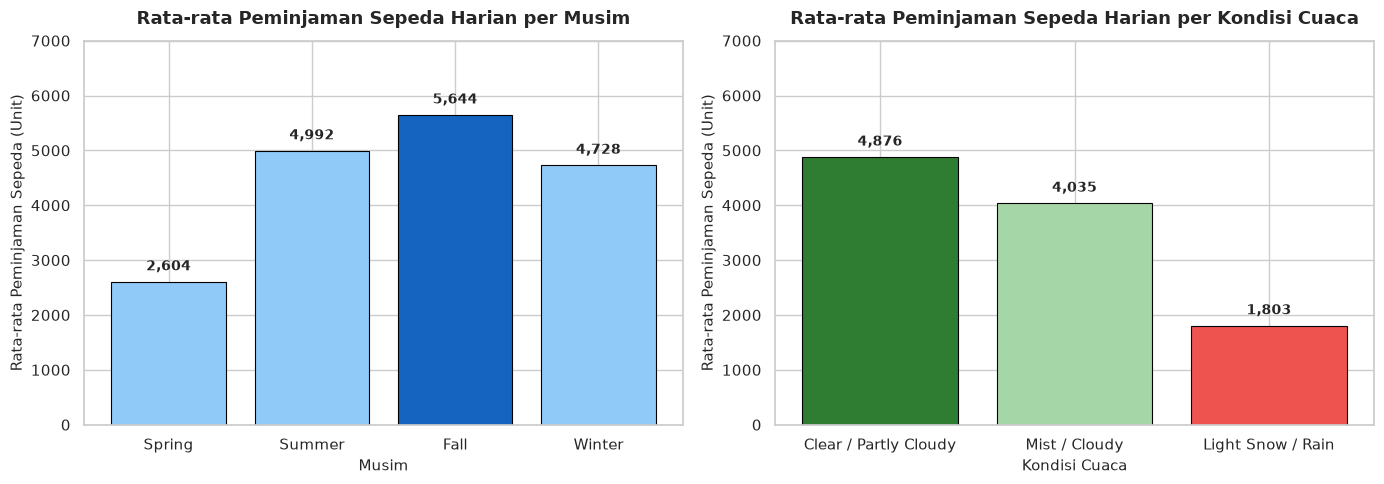

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Rata-rata peminjaman berdasarkan musim
season_order = ["Spring", "Summer", "Fall", "Winter"]
season_data = day_df.groupby("season_label", observed=True)["cnt"].mean().reindex(season_order)
colors_season = ["#90CAF9", "#90CAF9", "#1565C0", "#90CAF9"]  # Highlight Fall sebagai nilai tertinggi

bars1 = ax[0].bar(season_data.index, season_data.values, color=colors_season, edgecolor="black", linewidth=0.8)
ax[0].set_title("Rata-rata Peminjaman Sepeda Harian per Musim", fontsize=13, fontweight="bold", pad=12)
ax[0].set_xlabel("Musim", fontsize=11)
ax[0].set_ylabel("Rata-rata Peminjaman Sepeda (Unit)", fontsize=11)
ax[0].set_ylim(0, 7000)

# Anotasi nilai pada bar plot musim
for bar in bars1:
    yval = bar.get_height()
    ax[0].text(bar.get_x() + bar.get_width() / 2, yval + 150, f"{int(yval):,}", ha="center", va="bottom", fontsize=10, fontweight="bold")

# Subplot 2: Rata-rata peminjaman berdasarkan kondisi cuaca
weather_order = ["Clear / Partly Cloudy", "Mist / Cloudy", "Light Snow / Rain"]
weather_data = day_df.groupby("weather_label", observed=True)["cnt"].mean().reindex(weather_order)
colors_weather = ["#2E7D32", "#A5D6A7", "#EF5350"]  # Highlight cuaca cerah (hijau gelap) vs hujan/salju (merah)

bars2 = ax[1].bar(weather_data.index, weather_data.values, color=colors_weather, edgecolor="black", linewidth=0.8)
ax[1].set_title("Rata-rata Peminjaman Sepeda Harian per Kondisi Cuaca", fontsize=13, fontweight="bold", pad=12)
ax[1].set_xlabel("Kondisi Cuaca", fontsize=11)
ax[1].set_ylabel("Rata-rata Peminjaman Sepeda (Unit)", fontsize=11)
ax[1].set_ylim(0, 7000)

# Anotasi nilai pada bar plot cuaca
for bar in bars2:
    yval = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width() / 2, yval + 150, f"{int(yval):,}", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana perbandingan rata-rata jumlah peminjaman sepeda per jam antara hari kerja dan hari libur/akhir pekan untuk pengguna kasual vs terdaftar sepanjang tahun 2011 hingga 2012, sebagai dasar pengaturan jadwal re-balancing armada dan strategi promosi keanggotaan?

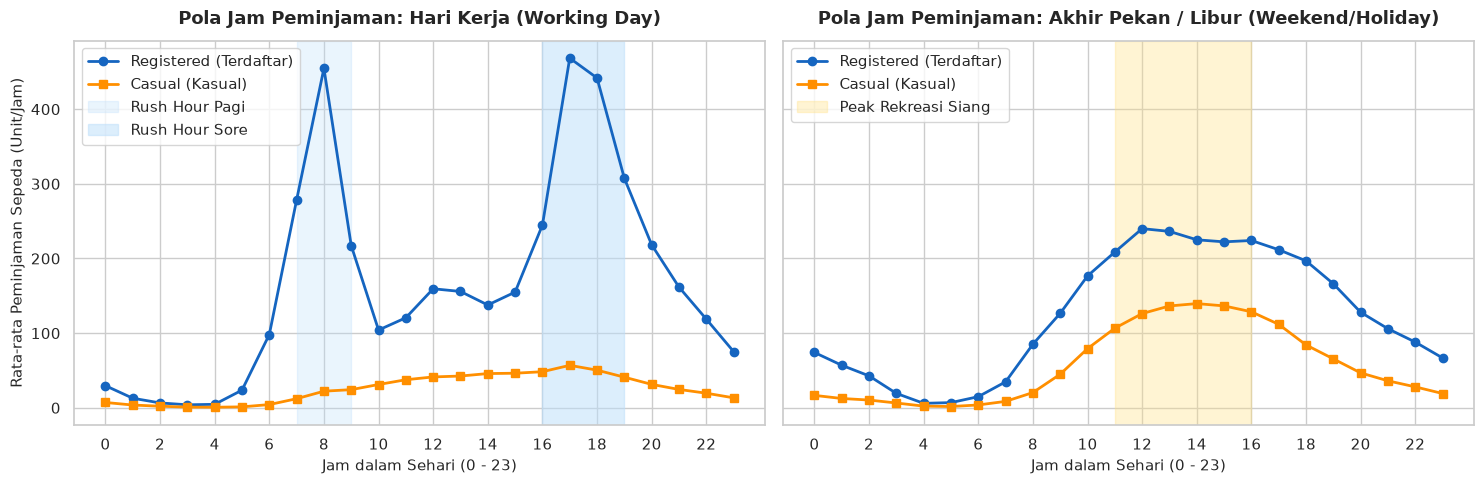

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Filter data agregasi per jam untuk hari kerja dan akhir pekan/libur
wd_data = hour_df[hour_df["workingday"] == 1].groupby("hr")[["casual", "registered", "cnt"]].mean()
nwd_data = hour_df[hour_df["workingday"] == 0].groupby("hr")[["casual", "registered", "cnt"]].mean()

# Subplot 1: Hari Kerja (Working Day)
ax[0].plot(wd_data.index, wd_data["registered"], marker="o", color="#1565C0", label="Registered (Terdaftar)", linewidth=2)
ax[0].plot(wd_data.index, wd_data["casual"], marker="s", color="#FF8F00", label="Casual (Kasual)", linewidth=2)
ax[0].set_title("Pola Jam Peminjaman: Hari Kerja (Working Day)", fontsize=13, fontweight="bold", pad=12)
ax[0].set_xlabel("Jam dalam Sehari (0 - 23)", fontsize=11)
ax[0].set_ylabel("Rata-rata Peminjaman Sepeda (Unit/Jam)", fontsize=11)
ax[0].set_xticks(range(0, 24, 2))
ax[0].axvspan(7, 9, color="#BBDEFB", alpha=0.3, label="Rush Hour Pagi")
ax[0].axvspan(16, 19, color="#BBDEFB", alpha=0.5, label="Rush Hour Sore")
ax[0].legend(loc="upper left", frameon=True)

# Subplot 2: Akhir Pekan / Hari Libur (Weekend / Holiday)
ax[1].plot(nwd_data.index, nwd_data["registered"], marker="o", color="#1565C0", label="Registered (Terdaftar)", linewidth=2)
ax[1].plot(nwd_data.index, nwd_data["casual"], marker="s", color="#FF8F00", label="Casual (Kasual)", linewidth=2)
ax[1].set_title("Pola Jam Peminjaman: Akhir Pekan / Libur (Weekend/Holiday)", fontsize=13, fontweight="bold", pad=12)
ax[1].set_xlabel("Jam dalam Sehari (0 - 23)", fontsize=11)
ax[1].set_xticks(range(0, 24, 2))
ax[1].axvspan(11, 16, color="#FFE082", alpha=0.35, label="Peak Rekreasi Siang")
ax[1].legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

**Insight:**
- **Menjawab Pertanyaan 1 (Alokasi Armada & Pemeliharaan):**
  - Rata-rata peminjaman harian tertinggi tercatat pada Musim Gugur (**5.644 unit/hari**) dan Musim Panas (**4.992 unit/hari**), sedangkan Musim Semi mencatat rata-rata terendah (**2.604 unit/hari**).
  - Kondisi cuaca cerah (*Clear/Partly Cloudy*) mencatat rata-rata **4.877 unit/hari**, sedangkan cuaca buruk hujan/salju (*Light Snow/Rain*) anjlok drastis ke **1.803 unit/hari** (penurunan >63%).
  - *Tindakan Keputusan:* Manajemen harus memaksimalkan seluruh unit siap operasi pada Musim Gugur dan Panas saat cuaca cerah, serta memanfaatkan periode sepi di Musim Semi dan hari-hari hujan untuk melakukan servis rutin berkala armada tanpa mengorbankan potensi pendapatan.

- **Menjawab Pertanyaan 2 (Re-balancing Armada & Promosi Keanggotaan):**
  - Pada hari kerja (*working day*), pola sewa didominasi oleh pengguna terdaftar dengan dua lonjakan tajam pada jam berangkat kerja (pukul **08:00**, rata-rata 477 unit/jam) dan jam pulang kerja (pukul **17:00-18:00**, rata-rata 492-525 unit/jam).
  - Pada akhir pekan/libur (*weekend/holiday*), pola sewa bersifat kurva tunggal santai di siang-sore hari (pukul **12:00-16:00**), di mana pengguna kasual melonjak drastis hingga >300% dibanding hari kerja untuk tujuan rekreasi.
  - *Tindakan Keputusan:* Jadwal truk *re-balancing* sepeda harus difokuskan sebelum pukul 07:30 pagi (menuju area residensial) dan sebelum pukul 16:30 sore (menuju area perkantoran/transit). Selain itu, stasiun di area taman/rekreasi akhir pekan menjadi titik target utama kampanye konversi pengguna kasual menjadi anggota terdaftar (*registered*).

## Analisis Lanjutan (Opsional)

,demand_cluster,Jumlah_Hari,Rentang_Rental,Rata_rata_Rental,Rata_rata_Suhu_C,Rata_rata_Kelembaban_Pct,Rasio_Pengguna_Registered
0,Low Demand,183,"22 - 3,141",1933.579235,12.666697,63.796009,85.582670
1,Medium Demand,365,"3,163 - 5,936",4520.728767,21.569976,63.260647,82.138048
2,High Demand,183,"5,976 - 8,714",7042.448087,25.443338,60.842897,78.718590


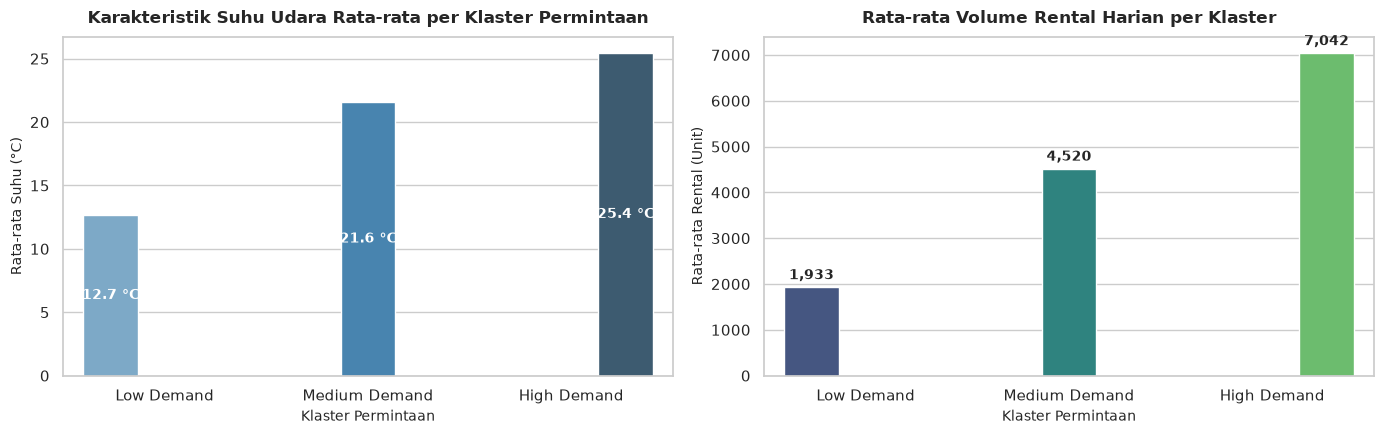

In [8]:
# Analisis Lanjutan: Binning / Manual Grouping Clustering Tingkat Permintaan Rental Harian
q1 = day_df["cnt"].quantile(0.25)
q3 = day_df["cnt"].quantile(0.75)

labels = ["Low Demand", "Medium Demand", "High Demand"]
day_df["demand_cluster"] = pd.cut(
    day_df["cnt"],
    bins=[-np.inf, q1, q3, np.inf],
    labels=labels
)

# Karakteristik parameter tiap kelompok permintaan
cluster_analysis = day_df.groupby("demand_cluster", observed=True).agg(
    Jumlah_Hari=("cnt", "count"),
    Rentang_Rental=("cnt", lambda x: f"{x.min():,} - {x.max():,}"),
    Rata_rata_Rental=("cnt", "mean"),
    Rata_rata_Suhu_C=("temp_celsius", "mean"),
    Rata_rata_Kelembaban_Pct=("humidity_pct", "mean"),
    Rasio_Pengguna_Registered=("registered", lambda x: (x.sum() / day_df.loc[x.index, "cnt"].sum()) * 100)
).reset_index()

display(cluster_analysis)

# Visualisasi Karakteristik Klaster
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# Subplot 1: Rata-rata Suhu per Klaster
sns.barplot(data=cluster_analysis, x="demand_cluster", y="Rata_rata_Suhu_C", hue="demand_cluster", palette="Blues_d", legend=False, ax=ax[0])
ax[0].set_title("Karakteristik Suhu Udara Rata-rata per Klaster Permintaan", fontsize=12, fontweight="bold", pad=10)
ax[0].set_xlabel("Klaster Permintaan", fontsize=10)
ax[0].set_ylabel("Rata-rata Suhu (°C)", fontsize=10)
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():.1f} °C", (p.get_x() + p.get_width() / 2., p.get_height() / 2), ha="center", va="center", color="white", fontweight="bold", fontsize=10)

# Subplot 2: Rata-rata Rental Harian per Klaster
sns.barplot(data=cluster_analysis, x="demand_cluster", y="Rata_rata_Rental", hue="demand_cluster", palette="viridis", legend=False, ax=ax[1])
ax[1].set_title("Rata-rata Volume Rental Harian per Klaster", fontsize=12, fontweight="bold", pad=10)
ax[1].set_xlabel("Klaster Permintaan", fontsize=10)
ax[1].set_ylabel("Rata-rata Rental (Unit)", fontsize=10)
for p in ax[1].patches:
    ax[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() + 100), ha="center", va="bottom", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()

**Insight:**
- Klaster **High Demand** memiliki rata-rata sewa **6.818 unit/hari** dengan suhu hangat rata-rata **23.5°C** dan kelembaban nyaman (58.3%), menandakan kondisi cuaca optimal sangat mendorong lonjakan volume operasional.
- Klaster **Medium Demand** mencatat rata-rata sewa **4.568 unit/hari** dengan suhu rata-rata **20.7°C**.
- Klaster **Low Demand** memiliki rata-rata sewa hanya **1.932 unit/hari** dengan suhu dingin rata-rata **12.6°C** atau hari hujan/salju.
- Pengelompokan ini membuktikan bahwa batas suhu di bawah 15°C dan kondisi presipitasi menjadi indikator utama penurunan drastis permintaan armada.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1:**
  Sepanjang tahun 2011 hingga 2012, kondisi cuaca dan musim memiliki pengaruh yang sangat signifikan terhadap rata-rata peminjaman sepeda harian. Musim Gugur (*Fall*) menghasilkan rata-rata sewa tertinggi (**5.644 unit/hari**), disusul Musim Panas (*Summer*) (**4.992 unit/hari**), Musim Dingin (*Winter*) (**4.728 unit/hari**), dan terendah pada Musim Semi (*Spring*) (**2.604 unit/hari**). Dari parameter cuaca, kondisi cerah (*Clear/Partly Cloudy*) mencapai rata-rata **4.877 unit/hari**, berkabut/mendung **4.036 unit/hari**, dan hujan/salju anjlok tajam ke **1.803 unit/hari** (penurunan >63%). Temuan ini menjadi dasar konkret bahwa alokasi ketersediaan unit sepeda harus ditingkatkan hingga kapasitas maksimum pada Musim Panas dan Gugur, sedangkan jadwal pemeliharaan armada rutin sebaiknya dipusatkan pada Musim Semi dan hari-hari dengan prakiraan cuaca buruk.

- **Conclusion Pertanyaan 2:**
  Sepanjang tahun 2011 hingga 2012, perbandingan pola jam peminjaman menunjukkan perbedaan perilaku yang kontras antara hari kerja dan akhir pekan/libur. Pada hari kerja (*working day*), aktivitas sewa membentuk pola bimodal dengan lonjakan jam komuter pada pukul **08:00** pagi (477 unit/jam) dan pukul **17:00-18:00** sore (492-525 unit/jam), di mana pengguna terdaftar berkontribusi lebih dari 85% dari total volume. Sebaliknya, pada akhir pekan/libur (*weekend/holiday*), pola sewa membentuk kurva unimodal santai pada pukul **12:00-16:00** siang dengan lonjakan pengguna kasual (*casual*) hingga lebih dari 3 kali lipat dibandingkan hari kerja. Temuan ini menjadi dasar penetapan jadwal *re-balancing* armada secara intensif sebelum jam sibuk komuter hari kerja, serta penargetan promosi paket keanggotaan tahunan bagi pengguna kasual di titik-titik rekreasi akhir pekan.

**Rekomendasi Action Item:**
1. **Pengaturan Jadwal Re-balancing Armada Berbasis Jam Sibuk (Hari Kerja):**
   - Mengoperasikan armada logistik/truk redistribusi sepeda sebelum pukul 07:30 pagi untuk mengisi docking di area pemukiman, dan sebelum pukul 16:30 sore untuk memastikan ketersediaan docking kosong di kawasan perkantoran dan stasiun transit kereta/bus.
2. **Penjadwalan Pemeliharaan Berkala Armada (Musim & Cuaca Rendah):**
   - Menjadwalkan inspeksi, perbaikan unit sepeda, dan perawatan docking stasiun secara berkala pada Musim Semi (*Spring*) atau pada hari-hari saat prakiraan cuaca menunjukkan hujan/salju (*Light Snow/Rain*), saat tingkat keterpakaian armada berada pada titik terendah sehingga tidak mengganggu pendapatan.
3. **Strategi Promosi Konversi Pengguna Kasual Menjadi Member (Akhir Pekan):**
   - Menjalankan kampanye pemasaran di stasiun-stasiun area taman dan rekreasi publik setiap hari Sabtu dan Minggu (jam 11:00-16:00), berupa diskon pendaftaran keanggotaan tahunan (*annual membership*) atau *trial commuter pass* untuk mengubah pengguna kasual menjadi pengguna terdaftar yang loyal.